In [8]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [9]:
from google.colab import files
uploaded = files.upload()

Saving ecommerce_rfm_practice.csv to ecommerce_rfm_practice.csv


In [10]:
df = pd.read_csv("ecommerce_rfm_practice.csv")

In [11]:
print(df.head())

    InvoiceNo  CustomerID InvoiceDate  Quantity  UnitPrice
0  INV1001001        1001  2026-09-04         3     841.03
1  INV1001002        1001  2026-09-16         1     249.38
2  INV1001003        1001  2026-09-07         3     635.53
3  INV1001004        1001  2026-08-28         3     595.48
4  INV1001005        1001  2026-09-04         4     891.28


In [12]:
df.tail()

,InvoiceNo,CustomerID,InvoiceDate,Quantity,UnitPrice
328,INV1058006,1058,2026-06-25,3,462.67
329,INV1059001,1059,2026-06-22,1,69.11
330,INV1059002,1059,2026-08-11,2,146.28
331,INV1060001,1060,2026-05-12,4,237.84
332,INV1060002,1060,2026-06-24,3,238.12


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    333 non-null    object 
 1   CustomerID   333 non-null    int64  
 2   InvoiceDate  333 non-null    object 
 3   Quantity     333 non-null    int64  
 4   UnitPrice    333 non-null    float64
dtypes: float64(1), int64(2), object(2)
memory usage: 13.1+ KB


In [14]:
df.describe()

,CustomerID,Quantity,UnitPrice
count,333.000000,333.000000,333.000000
mean,1029.837838,2.486486,471.707658
std,16.893112,1.099273,328.263878
min,1001.000000,1.000000,42.210000
25%,1016.000000,2.000000,245.330000
50%,1029.000000,3.000000,376.720000
75%,1045.000000,3.000000,627.470000
max,1060.000000,4.000000,2217.660000


In [15]:
df.isnull().sum()

,0
InvoiceNo,0
CustomerID,0
InvoiceDate,0
Quantity,0
UnitPrice,0


In [16]:
# 3. Calculate total amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [17]:
# 4. Calculate RFM
today = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (today - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

print("RFM Data:")
print(rfm.head())

RFM Data:
            Recency  Frequency  Monetary
CustomerID                              
1001             15          8  13546.30
1002             38          4   3578.61
1003             31          3   1166.34
1004            101          3   1079.20
1005              1         10  17114.83


In [18]:
# 5. Scale the data
scaler = StandardScaler()
X = scaler.fit_transform(rfm)

In [19]:
# 6. Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [20]:

# 7. Apply K-Means
km = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans"] = km.fit_predict(X)

In [21]:
# 8. Apply DBSCAN
db = DBSCAN(eps=0.8, min_samples=4)
rfm["DBSCAN"] = db.fit_predict(X)


print("\nCustomer Groups:")
print(rfm[["KMeans", "DBSCAN"]].head())


Customer Groups:
            KMeans  DBSCAN
CustomerID                
1001             3       0
1002             0       1
1003             0       1
1004             2       1
1005             3       0


In [22]:
# 9. Show customer profiles
print("\nMarketing Profiles:")
print(rfm.groupby("KMeans")[["Recency",
      "Frequency", "Monetary"]].median().round(2))


Marketing Profiles:
        Recency  Frequency  Monetary
KMeans                              
0          31.0        4.0   3822.10
1           2.0       14.0  22965.98
2         121.0        2.5   1067.18
3           2.0       10.0  14580.25


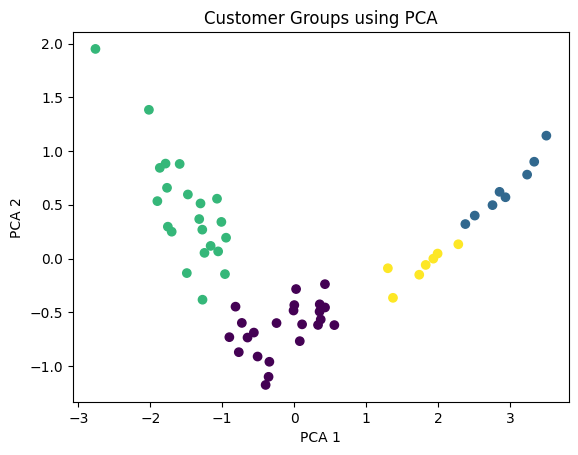

In [23]:
# 10. Visualize PCA
plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=rfm["KMeans"])
plt.title("Customer Groups using PCA")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()


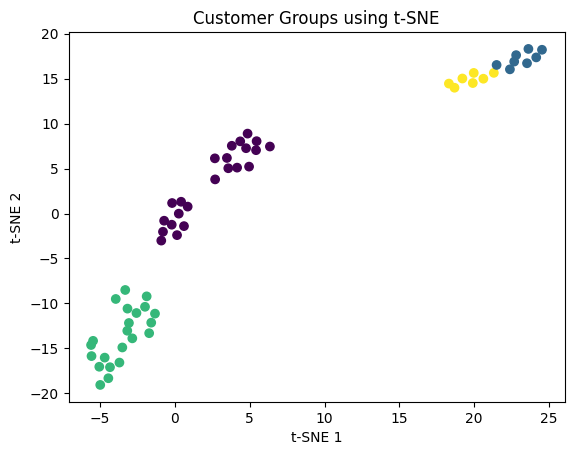

In [24]:
# 11. Visualize using t-SNE
tsne = TSNE(n_components=2, random_state=42,
            perplexity=10)
X_tsne = tsne.fit_transform(X_pca)

plt.scatter(X_tsne[:, 0], X_tsne[:, 1],
            c=rfm["KMeans"])
plt.title("Customer Groups using t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()


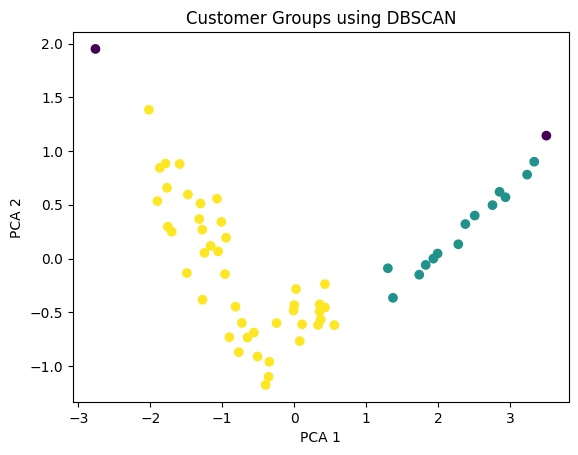

In [25]:
# DBSCAN Visualization using PCA

plt.scatter(X_pca[:, 0], X_pca[:, 1],
            c=rfm["DBSCAN"])

plt.title("Customer Groups using DBSCAN")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.show()

In [ ]:
## Conclusion

In this project, we performed E-Commerce Customer Segmentation using RFM analysis.

- RFM was used to understand customer purchasing behaviour.
- K-Means divided customers into 4 groups.
- DBSCAN identified dense customer groups and possible noise points.
- PCA reduced the dimensions of the dataset.
- t-SNE helped visualize customer segments in 2D.
- Marketing personas were created to suggest suitable business strategies.

This segmentation helps businesses improve customer engagement, customer retention, and marketing campaigns.